# Figure 7: what the Saturn cross pathways explain

From the five Saturn fits of Figs 2-6 to the Saturn panels of Fig. 7: per-spot decomposition and local cross gain, per-gene
cross test, cis concordance, what absorbs the ATAC cross term, the ATAC-steep zones, and the figure.

**No fit is rerun here.** This notebook starts from the fits. Each input and the notebook that makes it:

| Input | Made by |
|---|---|
| `lpc10_fov`: target, `saturn_best.pt`, `axes.csv`; chromVAR `tf_z_per_spot.npz`; RNA and ATAC AnnData (`arcseq_LPC10S1_*`) | `fig2_lpc` |
| `melanoma_tissue`: target, `saturn_best.pt`, `axes.csv`; chromVAR `tf_z_per_spot.npz`; `melanoma_rna.h5ad`, `atac_snap.h5ad` | `fig3_melanoma` |
| `rtt_merfish_s5_iso100_sv_pca_shrunk`: target, `_norestart_lc0.3/axes.csv`, `_norestart_lc0.3_weights/saturn_best.pt` | `fig4_merfish_isoform` |
| `sproxseq_B1_p46_dr`: target, `saturn_best.pt`; `sproxseq_B1_fig5/spots.csv` (axis orientation) | `fig5_sproxseq` |
| `mel_hic_abins_dr50_51_rnadr`: target, `saturn_best.pt`, `axes.csv` | `fig6_melanoma_hic` |
| RNA matrices (MERFISH, Sprox-seq B1, SpHIC117), GTFs | raw inputs, shared with Figs 4-6 |

**Lab intermediates that no notebook remakes:** `LPC10_lesion_FOV.h5mu` (cell2location proportions; `lpc10_fov_h5mu.py`, env `c2l`,
GPU), `starfysh_composition.csv` (Starfysh run), `LPC10S1_codex_per_spot.h5ad` (Catalign script 05; `fig2_lpc` recovers only its
coordinate part).

**Env:** `spatialmultivelo`, all steps. OMP unset. **Time:** about 30 min on a shared machine (cross term and mechanism 12 min, transect 14 min, figure 2 min; 15 min in total on a quieter machine).

**Panels dropped:** a and S6a, the GASTON benchmark. Their slots stay empty; every other panel comes from the builder, unmodified.
Whole-section R2 of Saturn is still shown in b.

In [1]:
import os, sys; sys.path.insert(0, ".")
from pathlib import Path
import nbutil as nb
nb.init("fig7")
HERE = Path(nb.__file__).resolve().parent; STEPS = HERE / "steps"; ENV = dict(SATURN_ROOT=str(nb.ROOT))
X = "results/real_saturn/saturn_cross_term"; KEYS = ["lpc10", "melanoma", "merfish", "sprox", "hic"]; ATAC = ["lpc10", "melanoma"]


def compare(what):
    """text columns, JSON, npz and pixel checks that nb.compare_table does not do"""
    if nb.PUB is None: print("SATURN_PUBLISHED not set: no comparison"); return
    nb.step(f"compare_{what}", f"python {STEPS}/fig7_compare.py {what}", extra_env=ENV); print(open(nb.HOLE / f"logs/compare_{what}.log").read())

ok      Hole/gaston_mix_mm/results/real_saturn/targets_lpc10_fov.npz  [Fig 2 target, made by notebook fig2_lpc]
ok      Hole/gaston_mix_mm/results/real_saturn/lpc10_fov/saturn_best.pt  [Fig 2 Saturn fit, made by notebook fig2_lpc]
ok      Hole/gaston_mix_mm/results/real_saturn/lpc10_fov/axes.csv  [Fig 2 Saturn axes, made by notebook fig2_lpc]
ok      Hole/gaston_mix_mm/results/real_saturn/targets_melanoma_tissue.npz  [Fig 3 target, made by notebook fig3_melanoma]
ok      Hole/gaston_mix_mm/results/real_saturn/melanoma_tissue/saturn_best.pt  [Fig 3 Saturn fit, made by notebook fig3_melanoma]
ok      Hole/gaston_mix_mm/results/real_saturn/melanoma_tissue/axes.csv  [Fig 3 Saturn axes, made by notebook fig3_melanoma]
ok      Hole/gaston_mix_mm/results/real_saturn/targets_sproxseq_B1_p46_dr.npz  [Fig 5 target, made by notebook fig5_sproxseq]
ok      Hole/gaston_mix_mm/results/real_saturn/sproxseq_B1_p46_dr/saturn_best.pt  [Fig 5 Saturn fit, made by notebook fig5_sproxseq]
ok      Hole/gasto

## 1. Cross term per dataset
From each saved model: own and cross term per spot, local cross gain (25-NN), gradients of both axes; per-gene hinge test of the
other axis beyond rho_RNA (partial F, BH), for genes detected in at least 5% of spots; for ATAC, the gene's +-50 kb accessibility
vs its cross profile against 200 random windows. Then the steepness test (200 rotations) and gene length.

In [2]:
for k in KEYS:
    nb.step(f"cross_term_{k}", f"python scripts/saturn_cross_term.py {k}", [f"{X}/{k}_spots.csv", f"{X}/{k}_genes.csv", f"{X}/{k}_profiles.npz", f"{X}/{k}_length.csv"])
for k in KEYS:
    nb.compare_table(f"saturn_cross_term/{k}_spots.csv"); nb.compare_table(f"saturn_cross_term/{k}_genes.csv")

[skip] cross_term_lpc10: outputs exist
[skip] cross_term_melanoma: outputs exist
[run ] cross_term_merfish: python scripts/saturn_cross_term.py merfish


[done] cross_term_merfish: 0.2 min


[skip] cross_term_sprox: outputs exist
[skip] cross_term_hic: outputs exist
saturn_cross_term/lpc10_spots.csv: shape (3425, 14) vs (3425, 14); max numeric diff 0; MATCH
saturn_cross_term/lpc10_genes.csv: shape (4476, 9) vs (4476, 9); max numeric diff 0; MATCH
saturn_cross_term/melanoma_spots.csv: shape (1997, 14) vs (1997, 14); max numeric diff 0; MATCH
saturn_cross_term/melanoma_genes.csv: shape (15347, 9) vs (15347, 9); max numeric diff 0; MATCH
saturn_cross_term/merfish_spots.csv: shape (2721, 14) vs (2721, 14); max numeric diff 0; MATCH
saturn_cross_term/merfish_genes.csv: shape (13374, 9) vs (13374, 9); max numeric diff 0; MATCH
saturn_cross_term/sprox_spots.csv: shape (3204, 14) vs (3204, 14); max numeric diff 0; MATCH
saturn_cross_term/sprox_genes.csv: shape (13100, 9) vs (13100, 9); max numeric diff 0; MATCH
saturn_cross_term/hic_spots.csv: shape (6108, 14) vs (6108, 14); max numeric diff 0; MATCH
saturn_cross_term/hic_genes.csv: shape (6360, 9) vs (6360, 9); max numeric diff 0

## 2. What absorbs the ATAC cross term (panel h)
For each cross-explained gene: the share of its gain from rho_ATAC absorbed by its own cis chromatin, TF activity, cell-type
composition, all three, or a rotated block of equal width. Also named drivers and each feature's boundary in the steep zones.

In [3]:
nb.step("mechanism", "python scripts/saturn_cross_mechanism.py", [f"{X}/{k}_mech_{t}" for k in ATAC for t in ("genes.csv", "drivers.csv", "boundary.csv", "summary.json")])
for k in ATAC:
    nb.compare_table(f"saturn_cross_term/{k}_mech_genes.csv")

[skip] mechanism: outputs exist
saturn_cross_term/lpc10_mech_genes.csv: shape (812, 12) vs (812, 12); max numeric diff 0; MATCH
saturn_cross_term/melanoma_mech_genes.csv: shape (5198, 12) vs (5198, 12); max numeric diff 0; MATCH


## 3. The ATAC-steep zones (panels g, i and S8)
The builder's `steep_cases` ranks the cross-explained genes by how much of their cross component sits in the steep zone; its cache
`fig7_steep.json` is an input of the transect. The transect runs across the largest steep zone along the gradient of rho_ATAC.
The follow-up gives zone switches (200 rotations), edge and depth controls, model vs raw gradients and CODEX boundaries.

In [4]:
nb.step("steep_cases", f"python {STEPS}/fig7_saturn_panels.py steep", [f"{X}/fig7_steep.json"], extra_env=ENV)
nb.step("transition", "python scripts/saturn_steep_transition.py", [f"{X}/{k}_transition_{t}" for k in ATAC for t in ("fits.csv", "profiles.csv", "spots.csv", "summary.json")])
nb.step("steep_followup", "python scripts/saturn_steep_followup.py", [f"{X}/steep_followup/followup.json", f"{X}/steep_followup/lpc10_codex.csv"])
for k in ATAC:
    nb.compare_table(f"saturn_cross_term/{k}_transition_fits.csv", tol=1e-4)
    nb.compare_table(f"saturn_cross_term/{k}_transition_profiles.csv")
    nb.compare_table(f"saturn_cross_term/steep_followup/{k}_zone_switch.csv")
nb.compare_table("saturn_cross_term/steep_followup/lpc10_codex.csv")

[skip] steep_cases: outputs exist
[skip] transition: outputs exist
[skip] steep_followup: outputs exist
saturn_cross_term/lpc10_transition_fits.csv: shape (65, 19) vs (65, 19); max numeric diff 0; MATCH
saturn_cross_term/lpc10_transition_profiles.csv: shape (18, 67) vs (18, 67); max numeric diff 0; MATCH
saturn_cross_term/steep_followup/lpc10_zone_switch.csv: shape (49, 4) vs (49, 4); max numeric diff 0; MATCH
saturn_cross_term/melanoma_transition_fits.csv: shape (68, 19) vs (68, 19); max numeric diff 0; MATCH
saturn_cross_term/melanoma_transition_profiles.csv: shape (18, 70) vs (18, 70); max numeric diff 0; MATCH
saturn_cross_term/steep_followup/melanoma_zone_switch.csv: shape (52, 4) vs (52, 4); max numeric diff 0; MATCH
saturn_cross_term/steep_followup/lpc10_codex.csv: shape (12, 4) vs (12, 4); max numeric diff 0; MATCH


{'file': 'saturn_cross_term/steep_followup/lpc10_codex.csv',
 'same_shape': True,
 'max_diff': 0.0}

## 4. All tables and summaries against published
Includes text columns (named drivers) and the JSON summaries (including `followup.json`).

In [5]:
for w in ("tables", "json"): compare(w)

[run ] compare_tables: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig7_compare.py tables


[done] compare_tables: 0.0 min


lpc10_spots.csv: (3425, 14); max|diff| 0 (x); NaN pattern diffs 0; text cells differing 0
lpc10_genes.csv: (4476, 9); max|diff| 0 (detect); NaN pattern diffs 0; text cells differing 0
lpc10_length.csv: (4456, 5); max|diff| 0 (length); NaN pattern diffs 0; text cells differing 0
melanoma_spots.csv: (1997, 14); max|diff| 0 (x); NaN pattern diffs 0; text cells differing 0
melanoma_genes.csv: (15347, 9); max|diff| 0 (detect); NaN pattern diffs 0; text cells differing 0
melanoma_length.csv: (11780, 5); max|diff| 0 (length); NaN pattern diffs 0; text cells differing 0
merfish_spots.csv: (2721, 14); max|diff| 0 (Unnamed: 0); NaN pattern diffs 0; text cells differing 0
merfish_genes.csv: (13374, 9); max|diff| 0 (detect); NaN pattern diffs 0; text cells differing 0
merfish_length.csv: (13366, 5); max|diff| 0 (length); NaN pattern diffs 0; text cells differing 0
sprox_spots.csv: (3204, 14); max|diff| 0 (x); NaN pattern diffs 0; text cells differing 0
sprox_genes.csv: (13100, 9); max|diff| 0 (det

[done] compare_json: 0.0 min


lpc10_summary.json: 85 values; max|diff| 0; text differing []; keys in one only []
melanoma_summary.json: 85 values; max|diff| 0; text differing []; keys in one only []
merfish_summary.json: 78 values; max|diff| 0; text differing []; keys in one only []
sprox_summary.json: 78 values; max|diff| 0; text differing []; keys in one only []
hic_summary.json: 78 values; max|diff| 0; text differing []; keys in one only []
lpc10_mech_summary.json: 12 values; max|diff| 0; text differing []; keys in one only []
lpc10_transition_summary.json: 7 values; max|diff| 0; text differing []; keys in one only []
melanoma_mech_summary.json: 12 values; max|diff| 0; text differing []; keys in one only []
melanoma_transition_summary.json: 7 values; max|diff| 0; text differing []; keys in one only []
fig7_steep.json: 54 values; max|diff| 0; text differing []; keys in one only []
steep_followup/followup.json: 55 values; max|diff| 0; text differing []; keys in one only []



## 5. Figure
`steps/fig7_saturn_panels.py` calls the builder's own layouts and panel functions, without a and S6a. Main panels b-i, supplements
S6b-f, S7 and S8. The builder's example cache `fig7_examples.npz` is rebuilt first, in its own process, as in the published run.

In [6]:
nb.step("examples", f"python {STEPS}/fig7_saturn_panels.py examples", [f"{X}/fig7_examples.npz"], extra_env=ENV)
nb.step("figure", f"python {STEPS}/fig7_saturn_panels.py", [nb.PF / "fig7/fig7_part3.png", nb.PF / "fig7/figS8_steepness_checks.png", nb.PF / "fig7/fig7_saturn_stats.json"], extra_env=ENV)
for w in ("npz", "stats", "pixels", "svg"): compare(w)

[run ] examples: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig7_saturn_panels.py examples


[done] examples: 0.3 min


[run ] figure: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig7_saturn_panels.py


[done] figure: 0.7 min


[run ] compare_npz: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig7_compare.py npz


[done] compare_npz: 0.1 min


... (3 outputs left out)

[done] compare_pixels: 0.1 min


fig7_part1: size (5054, 4030, 3) vs (5054, 4122, 3), tight crop without panel a
fig7_part1: 4030x5054; differing pixels 0.0395; over 8/255 0.0162; max 255
fig7_part2: 4620x5265; differing pixels 0; over 8/255 0; max 0
fig7_part3: 4301x4393; differing pixels 0; over 8/255 0; max 0
figS6_all_datasets: 4330x8450; differing pixels 0; over 8/255 0; max 0 (panel a slot masked: 0.52 W x 0.26 H)
figS7_gradient: 4140x5537; differing pixels 0; over 8/255 0; max 0
figS8_steepness_checks: 4077x3138; differing pixels 0; over 8/255 0; max 0
panels/fig7g_what_atac_steep_zone_marks: 4277x1079; differing pixels 0; over 8/255 0; max 0
panels/fig7h_what_atac_cross_term_reflects: 3895x1660; differing pixels 0; over 8/255 0; max 0
panels/fig7i_steep_zone_transition: 4269x1240; differing pixels 0; over 8/255 0; max 0
panels/fig7gi_steep_zone_block: 4277x2480; differing pixels 0; over 8/255 0; max 0

[run ] compare_svg: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig7_compare.py svg


[done] compare_svg: 0.0 min


fig7b_cross_term_R2_gain.svg: identical
fig7c_local_cross_gain_maps.svg: identical
fig7d_cross_explained_genes.svg: identical
fig7e_cis_chromatin_concordance.svg: identical
fig7f_cross_examples.svg: identical
fig7g_what_atac_steep_zone_marks.svg: identical
fig7gi_steep_zone_block.svg: identical
fig7h_what_atac_cross_term_reflects.svg: identical
fig7i_steep_zone_transition.svg: identical
figS6b_cross_term_R2_gain_all.svg: identical
figS6c_cross_explained_genes_all.svg: identical
figS6d_hic_long_genes.svg: identical
figS6e_local_cross_gain_maps_rest.svg: identical
figS6f_cross_examples_rest.svg: identical
figS7_gradient_vs_cross_gain.svg: identical
figS8_steepness_checks.svg: identical



One difference from the published PNGs is expected. `fig7_part1` has a smaller canvas because panel a is gone, and the tight crop
moves by a fraction of a pixel, so its pixels are not comparable; the per-panel SVG check is the exact test of b and c.

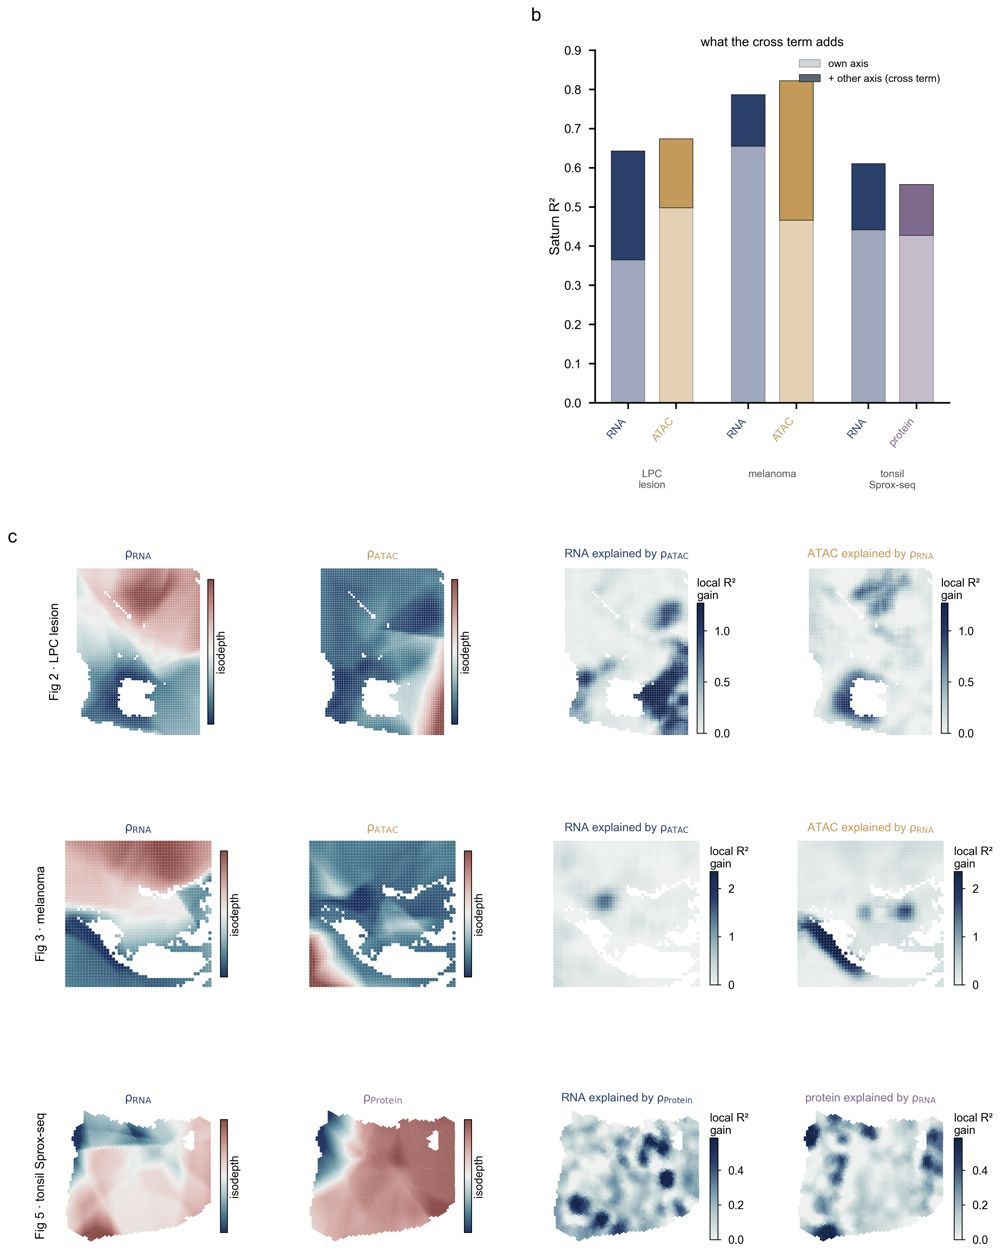

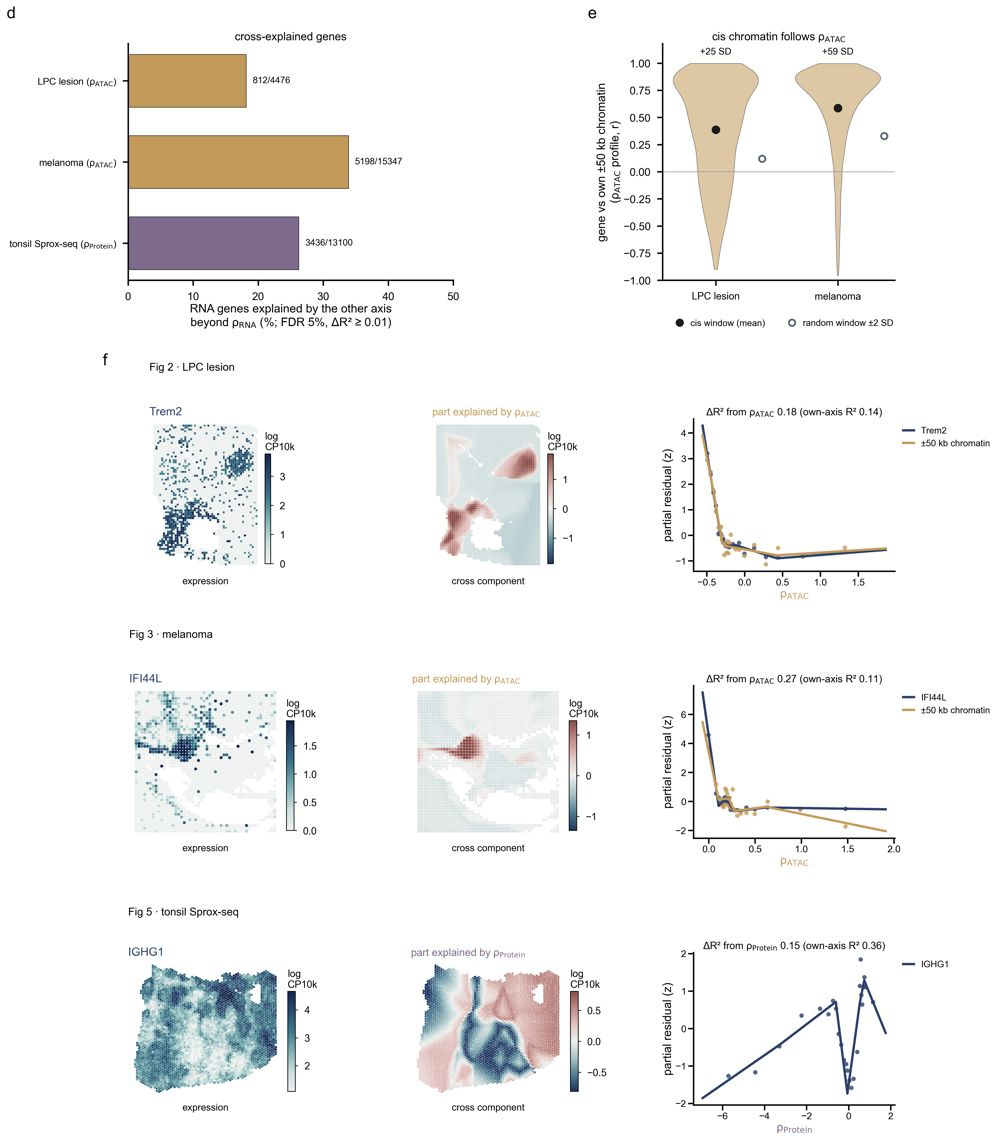

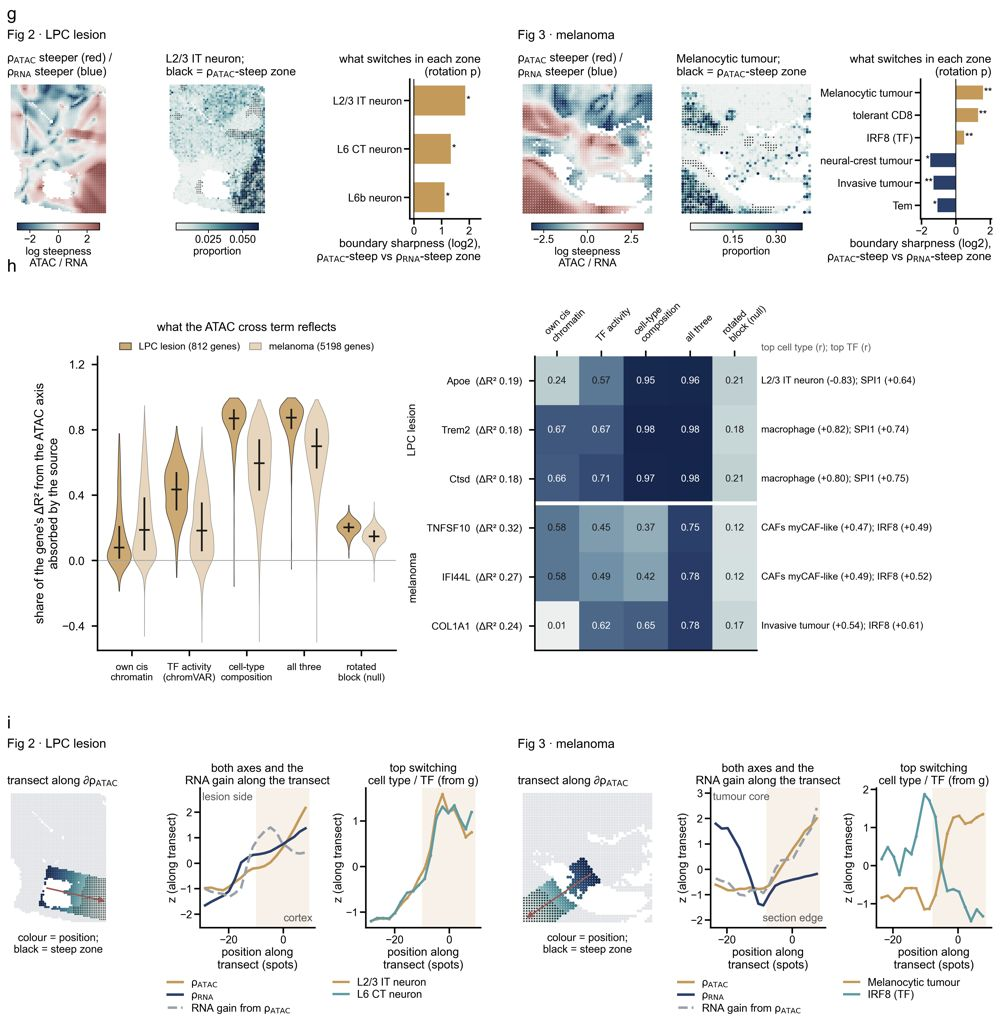

In [7]:
from PIL import Image
Image.MAX_IMAGE_PIXELS = None
for f in ("fig7_part1", "fig7_part2", "fig7_part3"):
    im = Image.open(nb.PF / f"fig7/{f}.png"); im.thumbnail((1000, 10 ** 5)); im.convert("RGB").save(nb.PF / f"fig7/{f}_preview.jpg", quality=80)
    nb.show(f"fig7/{f}_preview.jpg", width=800)